# Aiqon assignment
### Shipment ETA and delay propagation

Take-home for the Aiqon AI internship. The goal is to predict the final ETA of a shipment, estimate how likely and how large a delay is, and explain which stages of the journey cause it.

I first tried the Kaggle logistics and supply chain dataset, but as far as I could tell from its columns it describes each shipment with a single ETA variation value instead of timestamps for each stage, and none of my models beat a median baseline on it. That is not enough to study how a delay moves from one stage to the next, so I built a synthetic dataset of 300 shipments where every stage has a scheduled and an actual time.

One thing to keep in mind while reading the results: the data follows rules that I wrote (section 1). The scores tell us whether the method can recover that structure from noisy, partly missing data. They do not tell us how accurate it would be on real shipments.

Contents
1. Synthetic data
2. How ETA and delay are defined
3. Features
4. Models and evaluation
5. Explanations
6. Assumptions and limitations

To run it: `pip install -r requirements.txt`, then run all cells. Everything is seeded. Figures and tables are written to `outputs/` and the dataset to `data/`.

In [1]:
import os, sys, subprocess, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import GradientBoostingRegressor, GradientBoostingClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (mean_absolute_error, mean_squared_error, roc_auc_score,
                             f1_score, precision_score, recall_score)

warnings.filterwarnings("ignore")

try:
    import shap
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap"])
    import shap

os.makedirs("outputs", exist_ok=True)
os.makedirs("data", exist_ok=True)

SEED = 7
N_SHIPMENTS = 300
DELAY_LIMIT_H = 24      # a shipment counts as delayed if it arrives more than this late
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Synthetic data

Every shipment goes through five stages:

departure from origin port -> sea transit -> port handling at destination -> customs clearance -> final delivery (trucking)

Each stage has a scheduled time and an actual time. This is how the delays are put in:

- Routes: 8 routes (for example Shanghai to Los Angeles, Chennai to Singapore). A route fixes the distance, the planned port, customs and trucking hours, and whether customs offices are closed at weekends.
- Schedule: Built forward from the scheduled departure. Sea time is distance at 30 km/h, then the planned port, customs and trucking hours are added one after another.
- Departure delay: Gamma distributed. It gets longer when the origin port is congested, and bad weather at the origin adds more.
- Sea transit: The ship can win back some of the departure delay by speeding up (30% of it, capped at 4% of the sea time). Storms add delay, scaled by a route exposure factor.
- Port: Waiting for a berth grows with the square of congestion. A ship that arrives more than 12 hours late loses its slot and waits longer. Handling time grows with congestion and with the number of containers, so those two interact.
- Customs: Base time plus an inspection (more likely for hazardous cargo and in congested ports) plus a backlog term when the port stage ran long. On routes with weekend closures, a clearance that would land on Saturday or Sunday is pushed to Monday 09:00.
- Delivery: Trucks do not start after 17:00, and bad weather at the destination slows them down.
- External factors: Congestion at origin and destination (with a seasonal swing that peaks around July), and weather indices for origin, sea and destination. At departure we only get a noisy forecast of destination congestion. The real value is known once the ship arrives.
- Missing data: After the simulation, some intermediate timestamps are blanked (section 2).

In [2]:
# route table: the planned hours are what a carrier would publish
ROUTES = {
    "Shanghai-Los Angeles":  dict(origin="Shanghai",    dest="Los Angeles", km=10400, port_h=40, customs_h=24, truck_h=16, sea_expo=1.0, closed_wkend=True),
    "Busan-Long Beach":      dict(origin="Busan",       dest="Long Beach",  km=9200,  port_h=40, customs_h=24, truck_h=14, sea_expo=1.0, closed_wkend=True),
    "Nhava Sheva-Rotterdam": dict(origin="Nhava Sheva", dest="Rotterdam",   km=11500, port_h=36, customs_h=24, truck_h=18, sea_expo=0.8, closed_wkend=True),
    "Chennai-Singapore":     dict(origin="Chennai",     dest="Singapore",   km=2900,  port_h=24, customs_h=12, truck_h=8,  sea_expo=0.5, closed_wkend=False),
    "Singapore-Rotterdam":   dict(origin="Singapore",   dest="Rotterdam",   km=15500, port_h=36, customs_h=24, truck_h=18, sea_expo=0.9, closed_wkend=True),
    "Jebel Ali-Hamburg":     dict(origin="Jebel Ali",   dest="Hamburg",     km=11000, port_h=36, customs_h=24, truck_h=20, sea_expo=0.7, closed_wkend=True),
    "Mundra-Jebel Ali":      dict(origin="Mundra",      dest="Jebel Ali",   km=1900,  port_h=24, customs_h=12, truck_h=10, sea_expo=0.4, closed_wkend=False),
    "Colombo-Felixstowe":    dict(origin="Colombo",     dest="Felixstowe",  km=12000, port_h=36, customs_h=24, truck_h=14, sea_expo=0.9, closed_wkend=True),
}
# usual congestion level per port, 0 = empty, 1 = jammed
PORT_BASE = {"Shanghai": .45, "Busan": .35, "Nhava Sheva": .40, "Chennai": .35, "Singapore": .30,
             "Jebel Ali": .30, "Mundra": .30, "Colombo": .40, "Los Angeles": .55, "Long Beach": .55,
             "Rotterdam": .45, "Hamburg": .50, "Felixstowe": .55}
# cargo type: (inspection probability, relative container load)
CARGO = {"general": (.08, 1.0), "electronics": (.18, .8), "perishable": (.12, .6),
         "hazardous": (.35, .7), "machinery": (.15, 1.4)}
SPEED_KMH = 30.0


def port_congestion(port, t, rng):
    seasonal = 0.12 * np.sin(2 * np.pi * (t.dayofyear - 120) / 365)
    return float(np.clip(PORT_BASE[port] + seasonal + rng.normal(0, .10), 0.02, 0.98))


def next_monday_9am(t):
    days = (7 - t.weekday()) % 7 or 7
    return (t + pd.Timedelta(days=days)).normalize() + pd.Timedelta(hours=9)


def simulate(n, seed):
    rng = np.random.default_rng(seed)
    names = list(ROUTES)
    # shipments spread over 2024, sorted so the row order is chronological
    starts = pd.Timestamp("2024-01-01") + pd.to_timedelta(np.sort(rng.uniform(0, 365 * 24, n)), unit="h")
    rows = []
    for i, t0 in enumerate(starts):
        name = names[rng.integers(len(names))]
        r = ROUTES[name]
        cargo = rng.choice(list(CARGO), p=[.35, .2, .15, .1, .2])
        p_inspect, load = CARGO[cargo]
        teu = int(np.clip(rng.normal(20 * load, 6), 2, 60))

        # schedule
        planned_sea = r["km"] / SPEED_KMH
        s_dep = t0.round("h")
        s_arr = s_dep + pd.Timedelta(hours=planned_sea)
        s_rel = s_arr + pd.Timedelta(hours=r["port_h"])
        s_cus = s_rel + pd.Timedelta(hours=r["customs_h"])
        s_del = s_cus + pd.Timedelta(hours=r["truck_h"])

        # external factors
        o_cong = port_congestion(r["origin"], s_dep, rng)
        d_cong = port_congestion(r["dest"], s_arr, rng)
        d_cong_fc = float(np.clip(d_cong + rng.normal(0, .12), 0, 1))   # forecast we have at departure
        o_wx, sea_wx, d_wx = (float(np.clip(rng.beta(1.5, b), 0, 1)) for b in (4, 4.5, 4.5))

        # 1. departure
        dep_delay = rng.gamma(1.3, 1.5 + 9 * o_cong) + 14 * max(0, o_wx - .55) / .45 * rng.uniform(.5, 1.5)

        # 2. sea transit
        recovered = min(0.3 * dep_delay, 0.04 * planned_sea)
        sea_delay = -recovered + 45 * sea_wx ** 2 * r["sea_expo"] + rng.normal(0, 0.012 * planned_sea)
        arr_delay = dep_delay + sea_delay
        a_arr = s_arr + pd.Timedelta(hours=arr_delay)

        # 3. port: congestion x handling interaction, and the lost berth slot
        slot_lost = arr_delay > 12
        berth_wait = 30 * d_cong ** 2 * rng.gamma(2, .5)
        if slot_lost:
            berth_wait += rng.uniform(8, 24) * (.5 + d_cong)
        handling = 0.62 * r["port_h"] * (1 + .9 * d_cong) + 0.08 * teu * (.5 + d_cong) + rng.normal(0, 2)
        port_delay = berth_wait + handling - r["port_h"]
        a_rel = a_arr + pd.Timedelta(hours=berth_wait + handling)

        # 4. customs: inspection, backlog from the port stage, weekend closure
        inspected = rng.random() < p_inspect + .15 * d_cong
        customs_h = 0.65 * r["customs_h"] * rng.lognormal(0, .25) + inspected * rng.gamma(3, 7) + .3 * max(0, port_delay - 8)
        done = a_rel + pd.Timedelta(hours=customs_h)
        if r["closed_wkend"] and done.weekday() >= 5:
            done = next_monday_9am(done)
        a_cus = done

        # 5. delivery: trucks do not start after 17:00
        pickup = a_cus
        if pickup.hour >= 17:
            pickup = (pickup + pd.Timedelta(days=1)).normalize() + pd.Timedelta(hours=7)
        a_del = pickup + pd.Timedelta(hours=r["truck_h"] * rng.lognormal(0, .2) + 12 * d_wx ** 2)

        rows.append(dict(
            shipment_id=f"SH{i:04d}", route=name, origin=r["origin"], destination=r["dest"],
            cargo=cargo, teu=teu, distance_km=r["km"],
            sched_departure=s_dep, sched_port_arrival=s_arr, sched_port_release=s_rel,
            sched_customs_clear=s_cus, sched_delivery=s_del,
            actual_departure=s_dep + pd.Timedelta(hours=dep_delay), actual_port_arrival=a_arr,
            actual_port_release=a_rel, actual_customs_clear=a_cus, actual_delivery=a_del,
            origin_congestion=o_cong, dest_congestion=d_cong, dest_congestion_forecast=d_cong_fc,
            origin_weather=o_wx, sea_weather=sea_wx, dest_weather=d_wx, customs_inspected=int(inspected),
            planned_port_h=r["port_h"], planned_customs_h=r["customs_h"], planned_truck_h=r["truck_h"],
            customs_closed_wkend=int(r["closed_wkend"]),
        ))
    out = pd.DataFrame(rows)
    for c in out.columns[out.columns.str.startswith("actual_")]:
        out[c] = out[c].dt.round("min")     # minute resolution, like a real tracking feed
    return out


df = simulate(N_SHIPMENTS, SEED)
clean = df.copy()   # complete copy, only used for the stage breakdown in section 2
print(df.shape, "|", df.sched_departure.min().date(), "to", df.sched_departure.max().date())
df.head(3).T

(300, 28) | 2024-01-02 to 2024-12-29


,0,1,2
shipment_id,SH0000,SH0001,SH0002
route,Nhava Sheva-Rotterdam,Jebel Ali-Hamburg,Mundra-Jebel Ali
origin,Nhava Sheva,Jebel Ali,Mundra
destination,Rotterdam,Hamburg,Jebel Ali
cargo,general,perishable,electronics
teu,18,13,17
distance_km,11500,11000,1900
sched_departure,2024-01-02 09:00:00,2024-01-02 21:00:00,2024-01-02 22:00:00
sched_port_arrival,2024-01-18 08:20:00,2024-01-18 03:40:00,2024-01-05 13:20:00
sched_port_release,2024-01-19 20:20:00,2024-01-19 15:40:00,2024-01-06 13:20:00


## 2. How ETA and delay are defined

- Scheduled ETA is the scheduled delivery time.
- Delay at a milestone is actual time minus scheduled time, in hours. I call it the cumulative delay.
- Stage delay is the change in cumulative delay from one milestone to the next. It says how much a stage added or removed. The five stage delays add up exactly to the final delay (checked below), so a final delay can always be split by stage.
- Final delay is actual delivery minus scheduled delivery. This is the regression target. A shipment is delayed if the final delay is more than 24 hours. This is the classification target.
- Predicted ETA is scheduled delivery plus the predicted final delay.

Ground truth is simply what the simulator produced for the actual delivery time. No model output is used to define the labels.

Missing intermediate data: real tracking feeds have gaps, so I blank out 7% of port arrival, 6% of port release and 10% of customs clearance timestamps. The delivery time is never blanked because it is the label.

In [3]:
def hours(d, a, b):
    return (d[a] - d[b]).dt.total_seconds() / 3600

# targets
for d in (df, clean):
    d["final_delay_h"] = hours(d, "actual_delivery", "sched_delivery")
    d["delayed"] = (d["final_delay_h"] > DELAY_LIMIT_H).astype(int)

# stage delays from the complete data
dep    = hours(clean, "actual_departure", "sched_departure")
arr    = hours(clean, "actual_port_arrival", "sched_port_arrival")
rel    = hours(clean, "actual_port_release", "sched_port_release")
cus    = hours(clean, "actual_customs_clear", "sched_customs_clear")
final  = clean["final_delay_h"]
stages = pd.DataFrame({"departure": dep, "sea transit": arr - dep, "port handling": rel - arr,
                       "customs": cus - rel, "delivery": final - cus})
stages["route"] = clean["route"]

assert np.allclose(stages.drop(columns="route").sum(axis=1), final)   # stages add up to the final delay

print("final delay (hours):")
print(df["final_delay_h"].describe().round(1).to_string())
print("\nshare delayed (> %d h): %.1f%%" % (DELAY_LIMIT_H, 100 * df["delayed"].mean()))

# blank some intermediate timestamps
rng = np.random.default_rng(SEED + 1)
for col, share in [("actual_port_arrival", .07), ("actual_port_release", .06), ("actual_customs_clear", .10)]:
    df.loc[rng.random(len(df)) < share, col] = pd.NaT
print("\nmissing timestamps:")
print(df[["actual_port_arrival", "actual_port_release", "actual_customs_clear"]].isna().sum().to_string())

df.to_csv("data/shipments_synthetic.csv", index=False)

final delay (hours):
count    300.0
mean      25.0
std       25.5
min      -28.6
25%        4.1
50%       21.1
75%       41.8
max      122.7

share delayed (> 24 h): 46.0%

missing timestamps:
actual_port_arrival     22
actual_port_release     16
actual_customs_clear    31


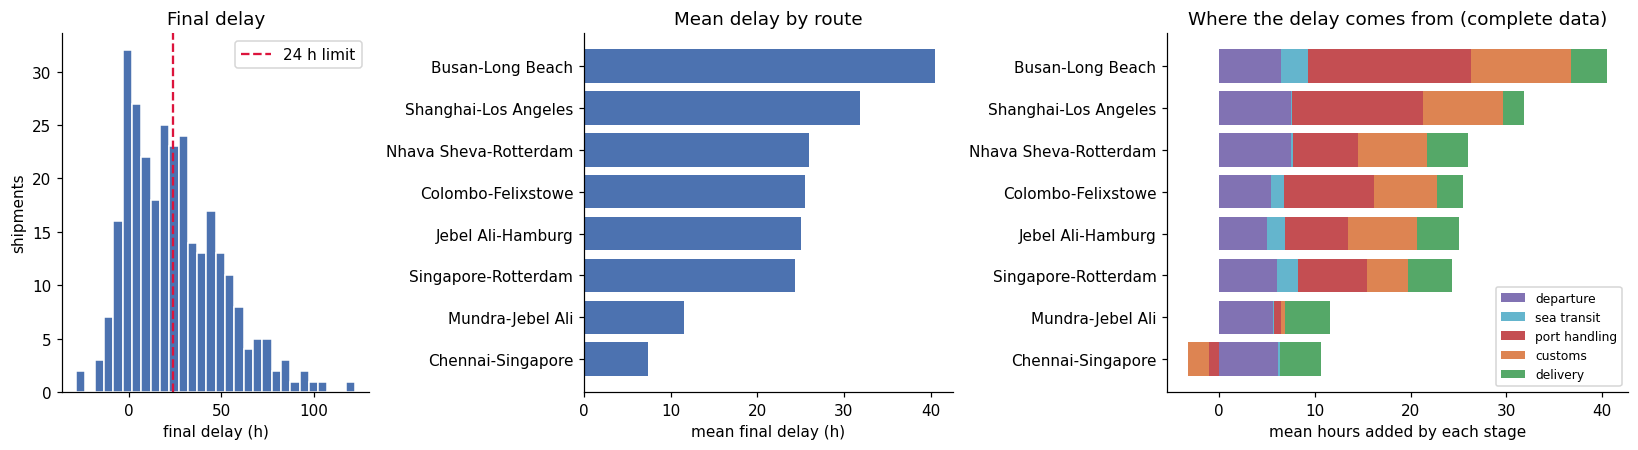

share of total mean delay by stage:
departure        0.25
sea transit      0.05
port handling    0.32
customs          0.23
delivery         0.15


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1, 1.2, 1.5]})

ax[0].hist(df["final_delay_h"], bins=30, color="#4C72B0", edgecolor="white")
ax[0].axvline(DELAY_LIMIT_H, color="crimson", ls="--", label=f"{DELAY_LIMIT_H} h limit")
ax[0].set_xlabel("final delay (h)"); ax[0].set_ylabel("shipments"); ax[0].legend()
ax[0].set_title("Final delay")

by_route = df.groupby("route")["final_delay_h"].mean().sort_values()
ax[1].barh(by_route.index, by_route.values, color="#4C72B0")
ax[1].set_xlabel("mean final delay (h)"); ax[1].set_title("Mean delay by route")

mean_stage = stages.groupby("route").mean(numeric_only=True).loc[by_route.index]
left_pos = np.zeros(len(mean_stage)); left_neg = np.zeros(len(mean_stage))
for col, c in zip(mean_stage.columns, ["#8172B3", "#64B5CD", "#C44E52", "#DD8452", "#55A868"]):
    v = mean_stage[col].values
    ax[2].barh(mean_stage.index, v, left=np.where(v >= 0, left_pos, left_neg), color=c, label=col)
    left_pos += np.clip(v, 0, None); left_neg += np.clip(v, None, 0)
ax[2].set_xlabel("mean hours added by each stage"); ax[2].set_title("Where the delay comes from (complete data)")
ax[2].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig("outputs/fig1_delay_overview.png", dpi=160)
plt.show()

print("share of total mean delay by stage:")
print((stages.drop(columns="route").mean() / final.mean()).round(2).to_string())

## 3. Features

A prediction is made at one of three checkpoints, using only what is known at that time:

1. Departure: schedule, route, cargo, origin congestion and weather, destination congestion forecast, departure delay.
2. Port arrival: adds the arrival delay, the delay picked up at sea, sea weather, actual destination congestion and the arrival day and hour.
3. Customs cleared: adds port and customs stage delays, whether the cargo was inspected, the clearance time, and destination weather.

Instead of predicting the final delay directly, the models predict the remaining delay: final delay minus the delay already carried at that checkpoint. The prediction is then `carried delay + predicted remaining delay`. This is how a delay propagates, because what is already late is carried forward and the model only has to learn what the rest of the journey adds or recovers. It also gives a simple way to deal with gaps: if a timestamp is missing, the latest available one is used as the carried delay.

Interaction features, to link stages instead of treating them separately:
- `arrival delay x destination congestion` (a late ship in a busy port)
- `congestion x planned port hours` and `congestion x container count` (congestion and processing time)
- `slot_missed`, arrival more than 12 h late
- the carried-forward clearance time (scheduled clearance plus carried delay): its weekday, its hour, whether it lands on a weekend at a port that closes, and whether it is after the 17:00 trucking cut-off

Missing values are filled with the training median and a missing-indicator column is added, so the model can tell that a stamp was absent.

In [5]:
F = pd.DataFrame(index=df.index)
F["route"], F["cargo"] = df["route"], df["cargo"]
for c in ["teu", "distance_km", "planned_port_h", "planned_customs_h", "planned_truck_h",
          "customs_closed_wkend", "origin_congestion", "origin_weather", "dest_congestion_forecast",
          "sea_weather", "dest_congestion", "customs_inspected", "dest_weather"]:
    F[c] = df[c]
F["dep_dow"] = df["sched_departure"].dt.dayofweek

# cumulative delays at each milestone (NaN when the timestamp is missing)
F["dep_delay_h"]     = hours(df, "actual_departure", "sched_departure")
F["arrival_delay_h"] = hours(df, "actual_port_arrival", "sched_port_arrival")
F["release_delay_h"] = hours(df, "actual_port_release", "sched_port_release")
F["customs_delay_h"] = hours(df, "actual_customs_clear", "sched_customs_clear")

# stage delays and interactions
F["transit_delay_h"]       = F["arrival_delay_h"] - F["dep_delay_h"]
F["port_stage_delay_h"]    = F["release_delay_h"] - F["arrival_delay_h"]
F["customs_stage_delay_h"] = F["customs_delay_h"] - F["release_delay_h"]
F["dep_x_cong_fc"]         = F["dep_delay_h"] * F["dest_congestion_forecast"]
F["arr_x_cong"]            = F["arrival_delay_h"] * F["dest_congestion"]
F["cong_x_planned_port"]   = F["dest_congestion"] * F["planned_port_h"]
F["cong_x_teu"]            = F["dest_congestion"] * F["teu"]
F["slot_missed"]           = (F["arrival_delay_h"] > 12).astype(float).where(F["arrival_delay_h"].notna())

# calendar features from the stamps
F["arrival_dow"]  = df["actual_port_arrival"].dt.dayofweek
F["arrival_hour"] = df["actual_port_arrival"].dt.hour
F["release_dow"]  = df["actual_port_release"].dt.dayofweek
F["release_hour"] = df["actual_port_release"].dt.hour
F["clear_hour"]   = df["actual_customs_clear"].dt.hour
F["after_cutoff"] = (F["clear_hour"] >= 17).astype(float).where(F["clear_hour"].notna())

CHECKPOINTS = ["1 departure", "2 port arrival", "3 customs cleared"]
static = ["route", "cargo", "teu", "distance_km", "planned_port_h", "planned_customs_h", "planned_truck_h",
          "customs_closed_wkend", "dep_dow", "origin_congestion", "origin_weather",
          "dest_congestion_forecast", "dep_delay_h", "dep_x_cong_fc"]
at_arrival = ["arrival_delay_h", "transit_delay_h", "sea_weather", "dest_congestion", "arrival_dow",
              "arrival_hour", "slot_missed", "arr_x_cong", "cong_x_planned_port", "cong_x_teu"]
at_customs = ["release_delay_h", "port_stage_delay_h", "release_dow", "release_hour", "customs_inspected",
              "customs_delay_h", "customs_stage_delay_h", "clear_hour", "after_cutoff", "dest_weather"]
FEATURES = {CHECKPOINTS[0]: static,
            CHECKPOINTS[1]: static + at_arrival,
            CHECKPOINTS[2]: static + at_arrival + at_customs}


def carried_delay(k):
    # latest cumulative delay we know at checkpoint k
    d = F["dep_delay_h"]
    if k == CHECKPOINTS[0]:
        return d
    a = F["arrival_delay_h"].fillna(d)
    if k == CHECKPOINTS[1]:
        return a
    return F["customs_delay_h"].fillna(F["release_delay_h"]).fillna(a)


def checkpoint_data(k):
    X = F[FEATURES[k]].copy()
    base = carried_delay(k)
    X["carried_delay_h"] = base
    # where would clearance land if the delay we carry stays the same?
    est = df["sched_customs_clear"] + pd.to_timedelta(base, unit="h")
    X["est_clear_dow"] = est.dt.dayofweek
    X["est_clear_hour"] = est.dt.hour
    X["est_clear_weekend_hold"] = ((est.dt.dayofweek >= 5) * F["customs_closed_wkend"]).astype(float)
    X["est_clear_late"] = (est.dt.hour >= 17).astype(float)
    return X, base


DATA = {k: checkpoint_data(k) for k in CHECKPOINTS}
for k in CHECKPOINTS:
    print(k, "->", DATA[k][0].shape[1], "features")

1 departure -> 19 features
2 port arrival -> 29 features
3 customs cleared -> 39 features


## 4. Models and evaluation

Split: shipments are in time order, so the first 75% (225) are used for training and the last 25% (75) for testing. Random splitting would let the model see the future.

Compared at every checkpoint:
- Schedule only: predict zero delay, so ETA = scheduled delivery. This is what you get if nobody updates the ETA.
- Route median: scheduled ETA plus the usual delay on that route.
- Carry forward: scheduled ETA plus the delay seen so far. A common rule of thumb in practice.
- Ridge and gradient boosting, both predicting the remaining delay.

Metrics: MAE and RMSE in hours for the ETA error. For the delayed / not delayed question: ROC AUC, and F1, precision and recall at a 0.5 threshold. For the classification baseline, the carry-forward rule says "delayed" when the carried delay is already over 24 h.

In [6]:
split = int(len(df) * 0.75)
train, test = df.index[:split], df.index[split:]
y = df["final_delay_h"]
yc = df["delayed"]
print("train:", len(train), " test:", len(test))
print("share delayed  train: %.2f   test: %.2f" % (yc[train].mean(), yc[test].mean()))


def make_pre(X):
    cat = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
    num = [c for c in X.columns if c not in cat]
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                          ("sc", StandardScaler())]), num),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
    ], verbose_feature_names_out=False)


REG = {
    "Ridge": Ridge(alpha=10),
    "Gradient boosting": GradientBoostingRegressor(n_estimators=250, learning_rate=0.03, max_depth=3,
                                                   subsample=0.8, min_samples_leaf=8, random_state=SEED),
}
CLF = {
    "Logistic regression": LogisticRegression(C=0.5, max_iter=2000),
    "Gradient boosting": GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=2,
                                                    subsample=0.8, min_samples_leaf=5, random_state=SEED),
}


def pipe(est, X):
    return Pipeline([("pre", make_pre(X)), ("m", clone(est))])


def mae_rmse(true, pred):
    return mean_absolute_error(true, pred), np.sqrt(mean_squared_error(true, pred))


route_median = y[train].groupby(df.loc[train, "route"]).median()
reg_rows, clf_rows, fitted = [], [], {}

for k in CHECKPOINTS:
    X, base = DATA[k]
    rem = y - base                      # remaining delay = what the later stages add
    preds = {
        "Schedule only": pd.Series(0.0, index=df.index),
        "Route median": df["route"].map(route_median).astype(float),
        "Carry forward": base,
    }
    models = {}
    for name, est in REG.items():
        p = pipe(est, X).fit(X.loc[train], rem[train])
        preds[name] = base + p.predict(X)
        models[name] = p
    for name, p in preds.items():
        mae, rmse = mae_rmse(y[test], p[test])
        reg_rows.append({"checkpoint": k, "method": name, "MAE_h": mae, "RMSE_h": rmse})

    # delayed or not
    probs = {"Carry forward": base}
    clfs = {}
    for name, est in CLF.items():
        c = pipe(est, X).fit(X.loc[train], yc[train])
        probs[name] = pd.Series(c.predict_proba(X)[:, 1], index=df.index)
        clfs[name] = c
    for name, s in probs.items():
        thr = DELAY_LIMIT_H if name == "Carry forward" else 0.5
        hard = (s[test] > thr).astype(int)
        clf_rows.append({"checkpoint": k, "method": name, "AUC": roc_auc_score(yc[test], s[test]),
                         "F1": f1_score(yc[test], hard), "precision": precision_score(yc[test], hard),
                         "recall": recall_score(yc[test], hard)})
    fitted[k] = dict(X=X, base=base, reg=models["Gradient boosting"], clf=clfs["Gradient boosting"])

reg_res = pd.DataFrame(reg_rows)
clf_res = pd.DataFrame(clf_rows)
reg_res.to_csv("outputs/results_eta_error.csv", index=False)
clf_res.to_csv("outputs/results_delay_classification.csv", index=False)

print("\nETA error on the test set (hours):")
display(reg_res.pivot(index="method", columns="checkpoint", values="MAE_h").round(1)
        .loc[["Schedule only", "Route median", "Carry forward", "Ridge", "Gradient boosting"]])
print("RMSE (hours):")
display(reg_res.pivot(index="method", columns="checkpoint", values="RMSE_h").round(1)
        .loc[["Schedule only", "Route median", "Carry forward", "Ridge", "Gradient boosting"]])
print("Delayed / not delayed on the test set:")
display(clf_res.set_index(["checkpoint", "method"]).round(2))

train: 225  test: 75
share delayed  train: 0.48   test: 0.39



ETA error on the test set (hours):


checkpoint,1 departure,2 port arrival,3 customs cleared
method,,,
Schedule only,22.5,22.5,22.5
Route median,17.1,17.1,17.1
Carry forward,19.8,17.7,4.9
Ridge,15.5,13.5,4.1
Gradient boosting,15.1,13.1,3.6


RMSE (hours):


checkpoint,1 departure,2 port arrival,3 customs cleared
method,,,
Schedule only,30.3,30.3,30.3
Route median,22.0,22.0,22.0
Carry forward,26.7,25.3,6.7
Ridge,20.5,17.5,5.7
Gradient boosting,20.3,17.0,4.9


Delayed / not delayed on the test set:


AUC    F1  precision  recall
checkpoint        method                                            
1 departure       Carry forward        0.61  0.00       0.00    0.00
                  Logistic regression  0.79  0.69       0.73    0.66
                  Gradient boosting    0.78  0.68       0.70    0.66
2 port arrival    Carry forward        0.63  0.00       0.00    0.00
                  Logistic regression  0.78  0.69       0.73    0.66
                  Gradient boosting    0.80  0.70       0.68    0.72
3 customs cleared Carry forward        0.97  0.89       0.96    0.83
                  Logistic regression  0.95  0.83       0.83    0.83
                  Gradient boosting    0.95  0.90       0.90    0.90

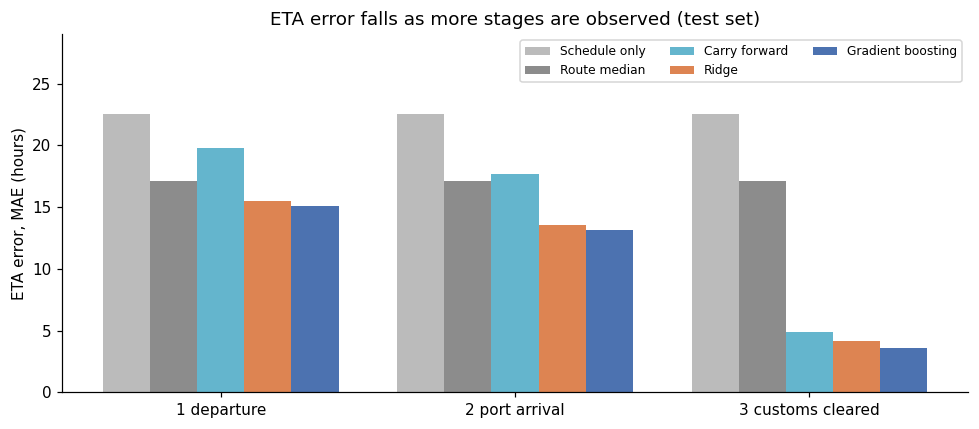

In [7]:
order = ["Schedule only", "Route median", "Carry forward", "Ridge", "Gradient boosting"]
colors = ["#BBBBBB", "#8C8C8C", "#64B5CD", "#DD8452", "#4C72B0"]
tab = reg_res.pivot(index="method", columns="checkpoint", values="MAE_h").loc[order]

fig, ax = plt.subplots(figsize=(9, 4))
w = 0.16
for i, (m, c) in enumerate(zip(order, colors)):
    ax.bar(np.arange(3) + (i - 2) * w, tab.loc[m].values, w, label=m, color=c)
ax.set_xticks(range(3)); ax.set_xticklabels(CHECKPOINTS)
ax.set_ylabel("ETA error, MAE (hours)")
ax.set_title("ETA error falls as more stages are observed (test set)")
ax.set_ylim(0, 29)
ax.legend(fontsize=8, ncol=3, loc="upper right")
plt.tight_layout()
plt.savefig("outputs/fig2_mae_by_checkpoint.png", dpi=160)
plt.show()

The test set is only 75 shipments, so one or two big misses can move a number a lot. As a second look I use an expanding-window time series split with 5 folds over all 300 shipments (always training on the past, testing on the next block). The out-of-fold predictions are also used to check errors by route and the effect of missing timestamps.

In [8]:
tscv = TimeSeriesSplit(n_splits=5)
cv_rows, oof = [], {}

for k in CHECKPOINTS:
    X, base = DATA[k]
    rem = y - base
    oof[k] = pd.Series(np.nan, index=df.index)
    for name, est in REG.items():
        maes = []
        for tr_idx, te_idx in tscv.split(X):
            p = pipe(est, X).fit(X.iloc[tr_idx], rem.iloc[tr_idx])
            pred = base.iloc[te_idx] + p.predict(X.iloc[te_idx])
            maes.append(mean_absolute_error(y.iloc[te_idx], pred))
            if name == "Gradient boosting":
                oof[k].iloc[te_idx] = pred
        cv_rows.append({"checkpoint": k, "method": name, "MAE mean": np.mean(maes), "MAE std": np.std(maes)})
    # reference rules on the same folds
    sched, carry = [], []
    for tr_idx, te_idx in tscv.split(X):
        sched.append(y.iloc[te_idx].abs().mean())
        carry.append(mean_absolute_error(y.iloc[te_idx], base.iloc[te_idx]))
    cv_rows.append({"checkpoint": k, "method": "Schedule only", "MAE mean": np.mean(sched), "MAE std": np.std(sched)})
    cv_rows.append({"checkpoint": k, "method": "Carry forward", "MAE mean": np.mean(carry), "MAE std": np.std(carry)})

cv_res = pd.DataFrame(cv_rows)
cv_res.to_csv("outputs/results_timeseries_cv.csv", index=False)
cv_view = cv_res.assign(MAE=lambda d: d["MAE mean"].round(1).astype(str) + " +/- " + d["MAE std"].round(1).astype(str))
display(cv_view.pivot(index="method", columns="checkpoint", values="MAE").loc[["Schedule only", "Carry forward", "Ridge", "Gradient boosting"]])

checkpoint,1 departure,2 port arrival,3 customs cleared
method,,,
Schedule only,27.5 +/- 3.3,27.5 +/- 3.3,27.5 +/- 3.3
Carry forward,23.4 +/- 2.6,21.7 +/- 2.7,5.9 +/- 0.5
Ridge,17.9 +/- 2.0,15.3 +/- 1.5,5.5 +/- 1.4
Gradient boosting,17.2 +/- 2.0,14.2 +/- 2.1,5.0 +/- 0.9


In [9]:
# errors by route and by missing data, from the out-of-fold predictions of the boosting model
scored = df.index[~oof[CHECKPOINTS[0]].isna()]
err = pd.DataFrame({k: (oof[k] - y).abs() for k in CHECKPOINTS}).loc[scored]
err["route"] = df.loc[scored, "route"]
by_route = err.groupby("route")[CHECKPOINTS].mean().round(1)
by_route.insert(0, "n", err.groupby("route").size())
by_route["mean delay (h)"] = y.loc[scored].groupby(df.loc[scored, "route"]).mean().round(1)
print("MAE by route (hours):")
display(by_route.sort_values(CHECKPOINTS[1]))
by_route.to_csv("outputs/results_by_route.csv")

has_gap = df[["actual_port_arrival", "actual_port_release", "actual_customs_clear"]].isna().any(axis=1).loc[scored]
gap_tab = err.groupby(has_gap.values)[CHECKPOINTS].mean().round(1)
gap_tab.index = ["all timestamps present", "at least one timestamp missing"]
gap_tab["n"] = has_gap.value_counts().reindex([False, True]).values
print("MAE with and without missing timestamps (hours):")
display(gap_tab)
gap_tab.to_csv("outputs/results_missing_data.csv")

MAE by route (hours):


,n,1 departure,2 port arrival,3 customs cleared,mean delay (h)
route,,,,,
Chennai-Singapore,19,13.9,11.7,3.1,8.1
Mundra-Jebel Ali,32,12.5,13.0,3.6,13.6
Jebel Ali-Hamburg,33,17.7,13.3,4.7,25.7
Nhava Sheva-Rotterdam,35,18.5,14.3,7.3,23.1
Busan-Long Beach,35,17.3,14.4,3.7,41.4
Shanghai-Los Angeles,35,18.3,14.9,7.1,32.6
Singapore-Rotterdam,25,20.6,15.3,6.0,26.9
Colombo-Felixstowe,36,18.2,15.4,3.6,27.1


MAE with and without missing timestamps (hours):


,1 departure,2 port arrival,3 customs cleared,n
all timestamps present,16.9,13.3,3.9,195
at least one timestamp missing,18.4,17.1,8.7,55


Do the engineered features help? Same time series split and the same boosting model, with groups of features removed.

In [10]:
INTERACTIONS = ["dep_x_cong_fc", "arr_x_cong", "cong_x_planned_port", "cong_x_teu", "slot_missed"]
CALENDAR = ["est_clear_dow", "est_clear_hour", "est_clear_weekend_hold", "est_clear_late"]
variants = {
    "plain stage delays only": INTERACTIONS + CALENDAR,
    "+ interactions": CALENDAR,
    "+ calendar timing": INTERACTIONS,
    "all features": [],
}


def cv_mae(k, drop):
    X, base = DATA[k]
    X = X.drop(columns=[c for c in drop if c in X.columns])
    rem = y - base
    maes = []
    for tr_idx, te_idx in tscv.split(X):
        p = pipe(REG["Gradient boosting"], X).fit(X.iloc[tr_idx], rem.iloc[tr_idx])
        maes.append(mean_absolute_error(y.iloc[te_idx], base.iloc[te_idx] + p.predict(X.iloc[te_idx])))
    return np.mean(maes)


ablation = pd.DataFrame({k: {name: cv_mae(k, drop) for name, drop in variants.items()} for k in CHECKPOINTS})
display(ablation.round(1))
ablation.round(2).to_csv("outputs/results_feature_ablation.csv")

,1 departure,2 port arrival,3 customs cleared
plain stage delays only,18.1,15.8,5.1
+ interactions,18.1,15.6,5.1
+ calendar timing,17.2,14.4,5.0
all features,17.2,14.2,5.0


Reading the results

- The error drops sharply once customs has cleared. By then most of the delay has already happened and only the trucking leg is left, so even the carry-forward rule is within about 5 hours. Boosting improves on it (3.6 h against 4.9 h on the test set, 5.0 against 5.9 in the time series split), mostly through the 17:00 trucking cut-off, which is the biggest group in the SHAP summary at that checkpoint.
- At departure and port arrival the error stays high. Boosting cuts the schedule-only error by about a third at departure and about 40% at port arrival (15.1 and 13.1 h against 22.5 h), but more than half a day of error remains. That is how the data is built: the largest random pieces (berth wait, inspections, weekend holds) come after the ship arrives, so they cannot be seen at those checkpoints. Ridge and boosting are close, so there is not much non-linear structure to find with 225 training rows.
- Carrying the delay forward is a weak rule early on. The delay picked up so far is small and the later stages add more on average, so it is worse than the route median at departure and no better at port arrival (17.7 h against 17.1 h).
- Delayed or not follows the same pattern: AUC around 0.8 at the first two checkpoints and 0.95 at the last. The carry-forward rule never fired on the test set before customs, which is why its F1 is 0 there.
- Routes: the short routes (Chennai-Singapore, Mundra-Jebel Ali) have the smallest errors at the first two checkpoints. At the last checkpoint Nhava Sheva-Rotterdam and Shanghai-Los Angeles stand out at about 7 h against 3 to 6 h for the rest, but with 35 shipments per route I would not read much into it.
- Missing timestamps hurt most at the last checkpoint (8.7 h with a gap against 3.9 h without). Falling back to the latest known delay stops it from falling apart, but it cannot give back the lost information. At departure nothing is missing yet, so the difference there (18.4 against 16.9) is only a different mix of shipments, which shows how noisy these small comparisons are.
- Features: the calendar timing features (weekday and hour of the carried-forward clearance time) give the clearest gain, about 1 hour at departure and 1.5 hours at port arrival, and nothing at the last checkpoint. The product features (congestion x handling and similar) add 0.2 h at most and nothing at the end. Boosting can build products by itself and the effect is smaller than the noise here, so I cannot claim they improve accuracy. I kept them because they are cheap, but this data does not show that they help.

## 5. Explanations

For the boosting models I use SHAP values. They split a prediction into a part per feature, and the parts add up to the prediction. I sum them by stage so the answer reads "port congestion added about X hours", not a list of columns.

Because the model predicts the remaining delay, the explanation has two parts:
1. delay already incurred, split by the stage where it appeared (from the observed timestamps)
2. delay still expected, split into a typical average plus a SHAP contribution per stage group

If a timestamp is missing, the delay of that stage is folded into the next available one, so the total still adds up.

,1 departure,2 port arrival,3 customs cleared
"Route, cargo, schedule",5.12,2.09,0.34
"Departure (origin congestion, weather)",2.71,1.41,0.63
Sea transit,0.00,2.29,0.34
Port arrival and congestion,3.32,6.55,0.86
Port release and customs,0.00,0.00,0.38
"Clearance timing (weekend, cut-off)",5.85,5.39,3.51
Delivery (weather),0.00,0.00,0.81
Delay carried so far,1.27,2.22,0.06


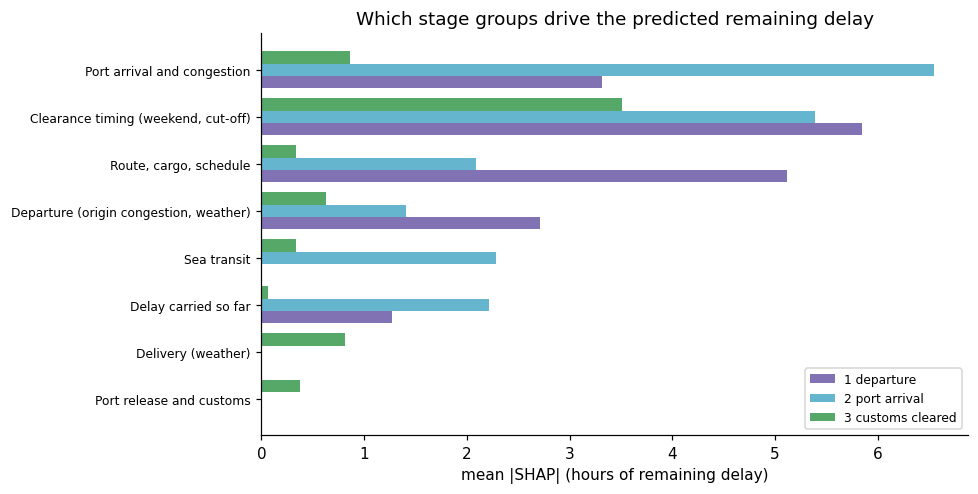

In [11]:
GROUPS = {
    "Route, cargo, schedule": ["teu", "distance_km", "planned_port_h", "planned_customs_h", "planned_truck_h",
                               "customs_closed_wkend", "dep_dow"],
    "Departure (origin congestion, weather)": ["origin_congestion", "origin_weather", "dep_delay_h"],
    "Sea transit": ["transit_delay_h", "sea_weather"],
    "Port arrival and congestion": ["dest_congestion_forecast", "dest_congestion", "dep_x_cong_fc", "arrival_delay_h",
                                    "arr_x_cong", "cong_x_planned_port", "cong_x_teu", "slot_missed",
                                    "arrival_dow", "arrival_hour"],
    "Port release and customs": ["release_delay_h", "port_stage_delay_h", "release_dow", "release_hour",
                                 "customs_inspected", "customs_delay_h", "customs_stage_delay_h"],
    "Clearance timing (weekend, cut-off)": ["clear_hour", "after_cutoff", "est_clear_dow", "est_clear_hour",
                                           "est_clear_weekend_hold", "est_clear_late"],
    "Delivery (weather)": ["dest_weather"],
    "Delay carried so far": ["carried_delay_h"],
}
GROUP_OF = {f: g for g, fs in GROUPS.items() for f in fs}


def group_of(name):
    name = name.replace("missingindicator_", "")
    if name.startswith("route_") or name.startswith("cargo_"):
        return "Route, cargo, schedule"
    return GROUP_OF[name]


def shap_by_group(k, rows):
    m = fitted[k]
    pre, gb = m["reg"].named_steps["pre"], m["reg"].named_steps["m"]
    names = pre.get_feature_names_out()
    sv = shap.TreeExplainer(gb).shap_values(pre.transform(m["X"].loc[rows]))
    groups = pd.Series([group_of(n) for n in names])
    return pd.DataFrame({g: sv[:, (groups == g).values].sum(axis=1) for g in GROUPS}, index=rows)


# how much each stage group moves the predicted remaining delay, averaged over the test set
imp = pd.DataFrame({k: shap_by_group(k, test).abs().mean() for k in CHECKPOINTS})
imp.round(2).to_csv("outputs/results_stage_importance.csv")
display(imp.round(2))

fig, ax = plt.subplots(figsize=(9, 4.6))
imp_plot = imp.loc[imp.max(axis=1).sort_values().index]
h = 0.26
for i, (k, c) in enumerate(zip(CHECKPOINTS, ["#8172B3", "#64B5CD", "#55A868"])):
    ax.barh(np.arange(len(imp_plot)) + (i - 1) * h, imp_plot[k], h, label=k, color=c)
ax.set_yticks(range(len(imp_plot))); ax.set_yticklabels(imp_plot.index, fontsize=8)
ax.set_xlabel("mean |SHAP| (hours of remaining delay)")
ax.set_title("Which stage groups drive the predicted remaining delay")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("outputs/fig3_stage_importance.png", dpi=160)
plt.show()

In [12]:
def explain_shipment(i, k, show=True):
    m = fitted[k]
    x = m["X"].loc[[i]]
    base = float(m["base"].loc[i])
    pre, gb = m["reg"].named_steps["pre"], m["reg"].named_steps["m"]
    explainer = shap.TreeExplainer(gb)
    sv = explainer.shap_values(pre.transform(x))[0]
    names = pre.get_feature_names_out()
    groups = pd.Series([group_of(n) for n in names])

    remaining = float(m["reg"].predict(x)[0])
    pred_delay = base + remaining
    p_late = float(m["clf"].predict_proba(x)[0, 1])

    # delay already incurred, by stage
    milestones = [("departure", F.loc[i, "dep_delay_h"]), ("sea transit", F.loc[i, "arrival_delay_h"]),
                  ("port handling", F.loc[i, "release_delay_h"]), ("customs", F.loc[i, "customs_delay_h"])]
    n_known = {0: 1, 1: 2, 2: 4}[CHECKPOINTS.index(k)]
    parts, prev = [], 0.0
    for label, cum in milestones[:n_known]:
        if pd.isna(cum):
            continue
        parts.append(("already incurred: " + label, cum - prev))
        prev = cum

    # delay still expected
    parts.append(("expected: typical remaining delay", float(np.ravel(explainer.expected_value)[0])))
    for g in GROUPS:
        parts.append(("expected: " + g, float(sv[(groups == g).values].sum())))
    table = pd.DataFrame(parts, columns=["component", "hours"])
    assert abs(table["hours"].sum() - pred_delay) < 1e-6

    eta = df.loc[i, "sched_delivery"] + pd.Timedelta(hours=pred_delay)
    if show:
        print(f"{df.loc[i, 'shipment_id']}  {df.loc[i, 'route']}  ({df.loc[i, 'cargo']}, {df.loc[i, 'teu']} TEU)  at checkpoint '{k}'")
        print(f"  scheduled delivery : {df.loc[i, 'sched_delivery']:%Y-%m-%d %H:%M}")
        print(f"  predicted delivery : {eta:%Y-%m-%d %H:%M}   ({pred_delay:+.1f} h)")
        print(f"  P(more than {DELAY_LIMIT_H} h late) : {p_late:.2f}")
        print(f"  actual delivery    : {df.loc[i, 'actual_delivery']:%Y-%m-%d %H:%M}   ({y[i]:+.1f} h)")
        top = table.loc[table["hours"].abs().sort_values(ascending=False).index].head(4)
        print("  biggest contributors: " + "; ".join(f"{r.component} ({r.hours:+.1f} h)" for r in top.itertuples()))
    return table, pred_delay, p_late


# one late and one early shipment from the test set (largest and smallest actual delay), at two checkpoints
late_i, early_i = y[test].idxmax(), y[test].idxmin()
for i in (late_i, early_i):
    for k in CHECKPOINTS[1:]:
        explain_shipment(i, k)
        print()

SH0251  Colombo-Felixstowe  (perishable, 7 TEU)  at checkpoint '2 port arrival'
  scheduled delivery : 2024-11-22 10:00
  predicted delivery : 2024-11-22 22:53   (+12.9 h)
  P(more than 24 h late) : 0.06
  actual delivery    : 2024-11-25 22:43   (+84.7 h)
  biggest contributors: expected: typical remaining delay (+19.1 h); expected: Sea transit (+4.4 h); expected: Route, cargo, schedule (-4.3 h); expected: Clearance timing (weekend, cut-off) (-4.2 h)

SH0251  Colombo-Felixstowe  (perishable, 7 TEU)  at checkpoint '3 customs cleared'
  scheduled delivery : 2024-11-22 10:00
  predicted delivery : 2024-11-26 05:03   (+91.1 h)
  P(more than 24 h late) : 0.99
  actual delivery    : 2024-11-25 22:43   (+84.7 h)
  biggest contributors: already incurred: customs (+68.8 h); already incurred: port handling (+16.6 h); expected: typical remaining delay (+5.2 h); expected: Clearance timing (weekend, cut-off) (-3.3 h)

SH0283  Shanghai-Los Angeles  (general, 21 TEU)  at checkpoint '2 port arrival'
 

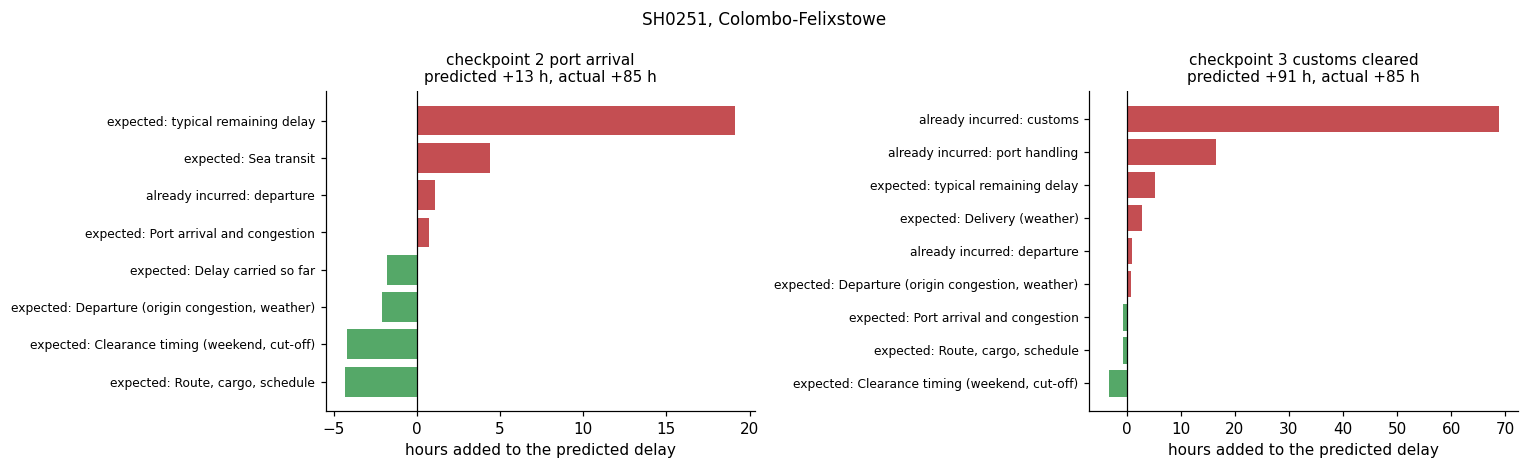

In [13]:
# same shipment at two checkpoints, to see how the explanation changes once port and customs are observed
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
for ax, k in zip(axes, CHECKPOINTS[1:]):
    t, pred, _ = explain_shipment(late_i, k, show=False)
    t = t[t["hours"].abs() > 0.5].sort_values("hours")
    ax.barh(t["component"], t["hours"], color=np.where(t["hours"] >= 0, "#C44E52", "#55A868"))
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlabel("hours added to the predicted delay")
    ax.set_title(f"checkpoint {k}\npredicted {pred:+.0f} h, actual {y[late_i]:+.0f} h", fontsize=10)
    ax.tick_params(axis="y", labelsize=8)
fig.suptitle(f"{df.loc[late_i, 'shipment_id']}, {df.loc[late_i, 'route']}", fontsize=11)
plt.tight_layout()
plt.savefig("outputs/fig4_one_shipment.png", dpi=160)
plt.show()

SH0251 is the test shipment with the largest delay, and it shows the limits of the checkpoint idea. Its port arrival timestamp was missing, so at checkpoint 2 the model only had the departure delay. It predicted about 13 hours late and the shipment was 85 hours late. The cargo was inspected, released on a Thursday afternoon, and clearance ran into the weekend, so it only came out on Monday morning. Nothing visible at port arrival pointed to that. At checkpoint 3 the explanation shows 69 hours incurred in customs and 17 in port handling, and the predicted ETA is about 6 hours off.

SH0283 is the opposite case, an early shipment. Both checkpoints put it on the right side of the 24 hour limit.

## 6. Assumptions and limitations

Assumptions
- All data is synthetic. Ground truth is the simulated actual delivery time, and a shipment is delayed when it is more than 24 hours behind schedule. The 24 hour limit is my choice.
- Schedules are padded with the average handling time, so the average delay is positive but not huge (a mean of about 25 hours, with 46% of shipments over the limit).
- The ETA is evaluated for the final delivery only, not for each intermediate milestone.
- Predictions are made at three fixed checkpoints, each using only information available at that moment. Destination congestion at departure is a noisy forecast.
- Timestamps are missing at random. Real gaps are probably not random (a vessel with a bad AIS signal may also be a more troubled one).

Limitations
- The strongest results are partly built in: weekend closures, the 17:00 cut-off and the slot loss are rules I put in the simulator, and I then built features to look for them. A real dataset would have effects that I did not think of, and some of mine might not exist.
- 300 shipments and a 75-row test set mean wide error bars. The time series split helps a little, but differences between ridge and boosting are within noise.
- Congestion has a seasonal swing that peaks in mid-year, so delays are not stationary. The test period (the last 75 shipments) has fewer delays than the training period (39% against 48%).
- SHAP values describe the model, not the cause. They are a good fit here because I know the real mechanism, but on real data they would be a starting point for investigation.
- No uncertainty intervals. A real ETA service should give a range (for example quantile regression), because users plan around the worst case.

With more time I would test on real port call or AIS data, add quantile predictions, and model the stages one by one (each stage predicted from the previous ones) to compare with the remaining-delay approach.

In [14]:
# save the main numbers in one place for the report
summary = {
    "n_shipments": int(len(df)), "n_train": int(len(train)), "n_test": int(len(test)),
    "delayed_share_all": float(df["delayed"].mean()), "delayed_share_train": float(yc[train].mean()),
    "delayed_share_test": float(yc[test].mean()), "mean_delay_h": float(y.mean()), "median_delay_h": float(y.median()),
}
pd.Series(summary).to_csv("outputs/summary.csv", header=["value"])
print(pd.Series(summary).round(3).to_string())

n_shipments            300.000
n_train                225.000
n_test                  75.000
delayed_share_all        0.460
delayed_share_train      0.484
delayed_share_test       0.387
mean_delay_h            24.989
median_delay_h          21.142
